# PROYECTO ATHENA — Hito 3: Adquisición, Preprocesado y Rendimientos

**Grado en Ciencia de Datos Aplicada — UOC**  
Autor: Álvaro Sánchez Mendoza | Tutor: Carlos Gaitán Poyatos  
Versión: 1.1.0 (incluye módulo de preprocesado)

---

## Descripción

Este notebook implementa el pipeline completo del Hito 3, incluyendo la incorporación
del módulo de preprocesado que estaba pendiente en la versión anterior.

| Actividad | Estado |
|-----------|--------|
| Conexión con la API de Yahoo Finance (yfinance) | ✅ Completado |
| Descarga de series históricas de precios ajustados | ✅ Completado |
| Preprocesado: eliminación de activos baja calidad | ✅ Completado |
| Preprocesado: interpolación de nulos aislados | ✅ Completado |
| Preprocesado: reindexado a días hábiles | ✅ Completado |
| Cálculo de rendimientos logarítmicos diarios | ✅ Completado |
| Estadísticas descriptivas básicas (EDA) | ✅ Completado |

## Estructura del notebook

1. Instalación y verificación de dependencias  
2. Importaciones y configuración  
3. Constantes y tickers  
4. Clase `DataAcquisition` — implementación completa  
5. Configuración del caso de uso  
6. Descarga de precios de cierre ajustados  
7. **Preprocesado de datos** *(nuevo)*  
8. Cálculo de rendimientos logarítmicos  
9. Estadísticas descriptivas anualizadas  
10. Resumen y outputs para el Hito 4  


## 1. Instalación y verificación de dependencias

Ejecuta la siguiente celda para instalar las dependencias necesarias.
Si ya están instaladas, el comando no produce ningún efecto.

In [69]:
# Instalación de dependencias (descomentar si es necesario)
# !pip install yfinance pandas numpy matplotlib

# Verificación de versiones instaladas
import importlib

dependencias = {
    'yfinance': '0.2.28',
    'pandas':   '2.0.0',
    'numpy':    '1.26.0',
}

print('Verificación de dependencias del Hito 3:')
print('-' * 45)
for paquete, version_min in dependencias.items():
    try:
        mod = importlib.import_module(paquete)
        version = getattr(mod, '__version__', 'desconocida')
        print(f'  {paquete:<12}: {version:<10} (mínimo requerido: {version_min})')
    except ImportError:
        print(f'  {paquete:<12}: NO INSTALADO — ejecuta: pip install {paquete}')
print('-' * 45)
print('Verificación completada.')


Verificación de dependencias del Hito 3:
---------------------------------------------
  yfinance    : 1.3.0      (mínimo requerido: 0.2.28)
  pandas      : 3.0.2      (mínimo requerido: 2.0.0)
  numpy       : 2.4.4      (mínimo requerido: 1.26.0)
---------------------------------------------
Verificación completada.


## 2. Importaciones y configuración

Importamos todas las librerías necesarias y configuramos el sistema de logging.

In [70]:
import logging
import warnings
from datetime import datetime
from pathlib import Path
from typing import Optional

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Suprimir avisos de deprecación externos
warnings.filterwarnings('ignore', category=FutureWarning)

# Configuración del logger para el notebook
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s  [%(levelname)s]  %(message)s',
    datefmt='%H:%M:%S',
)
logger = logging.getLogger('athena.hito3')

# Configuración visual de pandas
pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.max_columns', 12)
pd.set_option('display.width', 120)

# Estilo de gráficos
plt.rcParams.update({
    'figure.figsize':   (14, 5),
    'axes.spines.top':  False,
    'axes.spines.right':False,
    'axes.grid':        True,
    'grid.alpha':       0.3,
    'font.size':        10,
})

print('Importaciones completadas correctamente.')


Importaciones completadas correctamente.


## 3. Constantes y configuración de tickers

Definimos las listas de tickers predefinidas para el IBEX 35 y el S&P 500,
así como las constantes del módulo.

In [71]:
# ── Tickers del IBEX 35 (sufijo .MC = Mercado Continuo español) ──
IBEX35_TICKERS = [
    'SAN.MC', 'BBVA.MC', 'TEF.MC', 'ITX.MC', 'IBE.MC',
    'REP.MC', 'ACS.MC', 'FER.MC', 'CLNX.MC', 'AENA.MC',
    'AMS.MC', 'ACX.MC', 'ELE.MC', 'GRF.MC', 'IAG.MC',
    'IDR.MC', 'INM.MC', 'MAP.MC', 'MRL.MC', 'NTGY.MC',
    'PHM.MC', 'RED.MC', 'ROVI.MC', 'SAB.MC', 'SGRE.MC',
    'SLR.MC', 'VIS.MC', 'BKT.MC', 'MEL.MC', 'MTS.MC',
]

# ── Tickers del S&P 500 (sin sufijo = bolsa estadounidense) ──
SP500_TICKERS = [
    'AAPL', 'MSFT', 'AMZN', 'GOOGL', 'META',
    'NVDA', 'TSLA', 'BRK-B', 'UNH', 'JNJ',
    'JPM', 'V', 'PG', 'XOM', 'HD',
    'MA', 'CVX', 'ABBV', 'MRK', 'KO',
    'PEP', 'LLY', 'AVGO', 'TMO', 'COST',
    'MCD', 'DHR', 'WMT', 'ACN', 'NKE',
]

# ── Constantes financieras ──
TRADING_DAYS_YEAR = 252   # días hábiles anuales estándar

print(f'IBEX35 : {len(IBEX35_TICKERS)} activos definidos')
print(f'S&P 500: {len(SP500_TICKERS)} activos definidos')
print(f'TRADING_DAYS_YEAR = {TRADING_DAYS_YEAR}')


IBEX35 : 30 activos definidos
S&P 500: 30 activos definidos
TRADING_DAYS_YEAR = 252


## 4. Clase `DataAcquisition`

Implementación de la clase principal del módulo. Encapsula toda la lógica de
conexión con Yahoo Finance, descarga y transformación de datos.

In [72]:
class DataAcquisition:
    """
    Pipeline de adquisición y preprocesado de datos financieros.

    Versión 1.1: incluye módulo de preprocesado completo (5 pasos).

    Métodos
    ----------------
    download()               -> Descarga precios ajustados desde Yahoo Finance
    preprocess(prices)       -> Limpieza y preprocesado de los precios brutos
    compute_returns(prices)  -> Rendimientos logarítmicos diarios
    compute_annualized_stats(returns) -> Estadísticas EDA anualizadas
    """

    def __init__(self, tickers, start='2019-01-01', end=None,
                 interval='1d', cache_dir=None):
        if not tickers:
            raise ValueError('La lista de tickers no puede estar vacía.')
        self.tickers  = [t.upper().strip() for t in tickers]
        self.start    = start
        self.end      = end or datetime.today().strftime('%Y-%m-%d')
        self.interval = interval
        if cache_dir is not None:
            self.cache_dir = Path(cache_dir)
            self.cache_dir.mkdir(parents=True, exist_ok=True)
        else:
            self.cache_dir = None
        logger.info('DataAcquisition: %d activos | %s -> %s | freq: %s',
                    len(self.tickers), self.start, self.end, self.interval)

    # ── 1. DESCARGA ───────────────────────────────────────────────────
    def download(self, use_cache=True):
        """
        Descarga los precios de cierre ajustados desde Yahoo Finance.
        Usa caché local si está disponible. auto_adjust=True garantiza
        precios ajustados por dividendos y splits.
        """
        cache_path = self._cache_path('prices_raw')
        if use_cache and cache_path and cache_path.exists():
            logger.info('Cargando desde caché: %s', cache_path.name)
            df = pd.read_csv(cache_path, index_col=0, parse_dates=True)
            df.index.name = 'Date'
            return df

        logger.info('Descargando de Yahoo Finance: %d activos...', len(self.tickers))
        try:
            raw = yf.download(
                tickers=self.tickers, start=self.start, end=self.end,
                interval=self.interval, auto_adjust=True,
                progress=False, threads=True,
            )
        except Exception as exc:
            raise ConnectionError(f'Error en Yahoo Finance: {exc}') from exc

        if isinstance(raw.columns, pd.MultiIndex):
            prices = raw['Close'].copy()
        else:
            prices = raw[['Close']].copy()
            prices.columns = self.tickers[:1]

        if prices.empty:
            raise ValueError('La descarga no devolvió datos. Verifica los tickers.')

        prices.index = pd.to_datetime(prices.index)
        prices.index.name = 'Date'
        self._log_report(prices)

        if cache_path:
            prices.to_csv(cache_path)
            logger.info('Datos guardados: %s', cache_path.name)
        return prices

    # ── 2. PREPROCESADO ───────────────────────────────────────────────
    def preprocess(self, prices, min_valid_ratio=0.80, max_consec_nulls=5):
        """
        Pipeline de preprocesado en 5 pasos:
            1. Eliminar activos con > (1 - min_valid_ratio) de nulos.
            2. Interpolar linealmente nulos aislados (≤ max_consec_nulls).
            3. Eliminar filas enteramente nulas (festivos globales).
            4. Eliminar duplicados en el índice temporal.
            5. Reindexar al calendario completo de días hábiles.

        Parametros
        ----------
        prices : pd.DataFrame       Precios brutos de download()
        min_valid_ratio : float     Proporción mínima de datos válidos (def. 0.80)
        max_consec_nulls : int      Nulos consecutivos máximos a interpolar (def. 5)

        Returns
        -------
        pd.DataFrame  Precios limpios con índice de días hábiles.
        """
        logger.info('Preprocesado — shape inicial: %s', prices.shape)
        df = prices.copy()

        # Paso 1 — Eliminar activos con exceso de nulos
        valid_ratio = 1.0 - df.isna().mean()
        poor = valid_ratio[valid_ratio < min_valid_ratio].index.tolist()
        if poor:
            for a in poor:
                logger.warning('Paso 1 — Activo eliminado: %s (%.1f%% nulos)',
                               a, (1-valid_ratio[a])*100)
            df = df.drop(columns=poor)
        else:
            logger.info('Paso 1 — Todos los activos superan el umbral de calidad.')

        # Paso 2 — Interpolación lineal de nulos aislados
        n_before = int(df.isna().sum().sum())
        df = df.interpolate(method='linear', limit=max_consec_nulls,
                            limit_direction='both', axis=0)
        n_after = int(df.isna().sum().sum())
        logger.info('Paso 2 — Interpolación: %d nulos corregidos.', n_before - n_after)

        # Paso 3 — Eliminar filas enteramente nulas
        r_before = len(df)
        df = df.dropna(how='all')
        logger.info('Paso 3 — Filas nulas eliminadas: %d.', r_before - len(df))

        # Paso 4 — Eliminar duplicados en el índice
        n_dup = df.index.duplicated().sum()
        if n_dup:
            logger.warning('Paso 4 — %d índices duplicados eliminados.', n_dup)
            df = df[~df.index.duplicated(keep='first')]

        # Paso 5 — Reindexar a días hábiles completos
        bdays = pd.bdate_range(start=df.index.min(), end=df.index.max())
        r_before2 = len(df)
        df = df.reindex(bdays).ffill(limit=1)
        df.index.name = 'Date'
        logger.info('Paso 5 — Reindexado: %d filas añadidas.', len(df) - r_before2)

        nulls = df.isna().sum().sum()
        logger.info('Preprocesado completado — shape: %s | nulos residuales: %d',
                    df.shape, nulls)
        if nulls:
            logger.warning('%d nulos residuales (huecos > %d días). '
                           'Revisar activos afectados.', nulls, max_consec_nulls)

        cache_path = self._cache_path('prices_clean')
        if cache_path:
            df.to_csv(cache_path)
            logger.info('Datos limpios guardados: %s', cache_path.name)
        return df

    # ── 3. RENDIMIENTOS LOGARÍTMICOS ──────────────────────────────────
    def compute_returns(self, prices):
        """
        Calcula rendimientos logarítmicos diarios: r_t = ln(P_t / P_{t-1}).
        Se prefiere el log-rendimiento por aditividad temporal, simetría
        estadística y ser el estándar en la literatura financiera.
        """
        logger.info('Calculando rendimientos logarítmicos...')
        returns = np.log(prices / prices.shift(1)).iloc[1:]
        if returns.empty:
            raise ValueError('DataFrame de precios con menos de 2 filas.')
        logger.info('Rendimientos: %d obs × %d activos | media=%.6f | std=%.6f',
                    len(returns), returns.shape[1],
                    returns.mean().mean(), returns.std().mean())
        cache_path = self._cache_path('returns')
        if cache_path:
            returns.to_csv(cache_path)
            logger.info('Rendimientos guardados: %s', cache_path.name)
        return returns

    # ── 4. ESTADÍSTICAS ANUALIZADAS ───────────────────────────────────
    def compute_annualized_stats(self, returns):
        """Estadísticas descriptivas anualizadas para el panel EDA."""
        stats = pd.DataFrame(index=returns.columns)
        stats['Rendimiento anual (%)'] = (returns.mean() * TRADING_DAYS_YEAR * 100).round(2)
        stats['Volatilidad anual (%)'] = (returns.std() * np.sqrt(TRADING_DAYS_YEAR) * 100).round(2)
        stats['Ratio de Sharpe'] = (
            stats['Rendimiento anual (%)'] /
            stats['Volatilidad anual (%)'].replace(0, np.nan)
        ).round(4)
        stats['Asimetría'] = returns.skew().round(4)
        stats['Curtosis']  = returns.kurt().round(4)
        stats['Máx. Drawdown (%)'] = returns.apply(self._max_drawdown).round(2)
        return stats

    # ── Métodos privados ──────────────────────────────────────────────
    def _cache_path(self, name):
        if self.cache_dir is None: return None
        return self.cache_dir / f'{name}_{self.start}_{self.end}_{self.interval}.csv'

    def _log_report(self, prices):
        logger.info('Descargados: %d activos | %s -> %s | %d días',
                    prices.shape[1], prices.index.min().date(),
                    prices.index.max().date(), len(prices))
        for t, pct in (prices.isna().mean()*100).items():
            if pct > 0:
                logger.warning('  %s: %.1f%% nulos', t, pct)

    @staticmethod
    def _max_drawdown(series):
        cum = (1 + series).cumprod()
        return float(((cum - cum.cummax()) / cum.cummax()).min() * 100)


print('Clase DataAcquisition v1.1 definida (incluye preprocess()).')


Clase DataAcquisition v1.1 definida (incluye preprocess()).


## 5. Configuración de la demostración

Definimos los parámetros para el caso de uso del Hito 3:
una cartera de 8 activos del IBEX 35 con 5 años de histórico.

In [73]:
# ── Parámetros del caso de uso ────────────────────────────────────
TICKERS = [
    'SAN.MC',  # Banco Santander
    'BBVA.MC', # BBVA
    'TEF.MC',  # Telefónica
    'ITX.MC',  # Inditex
    'IBE.MC',  # Iberdrola
    'REP.MC',  # Repsol
    'ACS.MC',  # ACS
    'FER.MC',  # Ferrovial
]

START_DATE = '2019-01-01'
END_DATE   = '2024-12-31'
data = 'data/cache'
CACHE_DIR  = Path(data)

print(f'Activos seleccionados : {TICKERS}')
print(f'Período               : {START_DATE} -> {END_DATE}')
print(f'Directorio de caché   : {CACHE_DIR}')


Activos seleccionados : ['SAN.MC', 'BBVA.MC', 'TEF.MC', 'ITX.MC', 'IBE.MC', 'REP.MC', 'ACS.MC', 'FER.MC']
Período               : 2019-01-01 -> 2024-12-31
Directorio de caché   : data\cache


## 6. Descarga de precios de cierre ajustados

Inicializamos el pipeline y descargamos los precios históricos.
La primera ejecución conecta con Yahoo Finance; las siguientes usan la caché local.

In [74]:
# Inicializar el pipeline
pipeline = DataAcquisition(
    tickers   = TICKERS,
    start     = START_DATE,
    end       = END_DATE,
    cache_dir = CACHE_DIR,
)

# Descargar precios brutos (use_cache=True evita descargas redundantes)
prices_raw = pipeline.download(use_cache=True)

print(f'Resultados de la descarga:')
print(f'  Shape          : {prices_raw.shape}')
print(f'  Período real   : {prices_raw.index.min().date()} -> {prices_raw.index.max().date()}')
print(f'  Nulos totales  : {prices_raw.isna().sum().sum()}')


19:30:13  [INFO]  DataAcquisition: 8 activos | 2019-01-01 -> 2024-12-31 | freq: 1d
19:30:13  [INFO]  Cargando desde caché: prices_raw_2019-01-01_2024-12-31_1d.csv


Resultados de la descarga:
  Shape          : (1536, 8)
  Período real   : 2019-01-02 -> 2024-12-30
  Nulos totales  : 0


### Inspección de los datos descargados

In [75]:
# Primeras 5 filas de precios brutos
print('Primeras 5 filas (precios brutos):')
print(prices_raw.head())
print()
print('Últimas 5 filas (precios brutos):')
print(prices_raw.tail())
print()
print('Info del DataFrame:')
prices_raw.info()


Primeras 5 filas (precios brutos):
            ACS.MC  BBVA.MC  FER.MC  IBE.MC  ITX.MC  REP.MC  SAN.MC  TEF.MC
Date                                                                       
2019-01-02 20.9031   3.1369 15.0195  5.1173 17.7379  8.9691  3.0204  4.3287
2019-01-03 20.9534   3.1453 15.0958  5.1261 17.4848  8.9817  3.0447  4.4006
2019-01-04 21.2678   3.2627 15.2781  5.1641 18.1016  9.1959  3.1586  4.4579
2019-01-07 21.3370   3.2513 15.3926  5.2036 18.2440  9.1203  3.1764  4.4982
2019-01-08 21.5571   3.2789 15.5411  5.1846 18.6394  9.1298  3.2026  4.4912

Últimas 5 filas (precios brutos):
            ACS.MC  BBVA.MC  FER.MC  IBE.MC  ITX.MC  REP.MC  SAN.MC  TEF.MC
Date                                                                       
2024-12-20 45.5532   8.7859 39.1696 12.3382 48.3543  9.8609  4.2283  3.6464
2024-12-23 45.4764   8.7840 39.3859 12.3665 47.7554  9.9505  4.2041  3.6325
2024-12-24 45.9563   8.7519 39.8578 12.4233 47.8231 10.0221  4.1939  3.6325
2024-12-27 46.0907

### Estadísticas básicas de los precios descargados

In [76]:
# Estadísticas descriptivas básicas de los precios brutos
print('Estadísticas de los precios de cierre ajustados (brutos):')
print(prices_raw.describe().round(2))


Estadísticas de los precios de cierre ajustados (brutos):
         ACS.MC   BBVA.MC    FER.MC    IBE.MC    ITX.MC    REP.MC    SAN.MC    TEF.MC
count 1536.0000 1536.0000 1536.0000 1536.0000 1536.0000 1536.0000 1536.0000 1536.0000
mean    24.0400    4.7400   24.6700    8.8500   26.9300    9.3900    2.8800    3.2400
std      7.6800    2.1300    5.7100    1.7100    8.7900    2.3300    0.7600    0.6300
min      7.6900    1.6200   15.0200    5.1200   16.4700    3.7300    1.2300    1.8000
25%     18.4100    3.3700   20.8400    7.8900   20.7000    7.9300    2.3900    2.7500
50%     22.5800    3.9600   22.9700    8.8000   23.8500    9.5100    2.8400    3.1500
75%     27.1500    5.9900   27.2700    9.8100   30.9100   11.2900    3.2500    3.6900
max     46.2100   10.0600   40.3500   13.4000   54.0700   14.0000    4.6300    4.5800


### Visualización — Evolución histórica de precios (base 100)

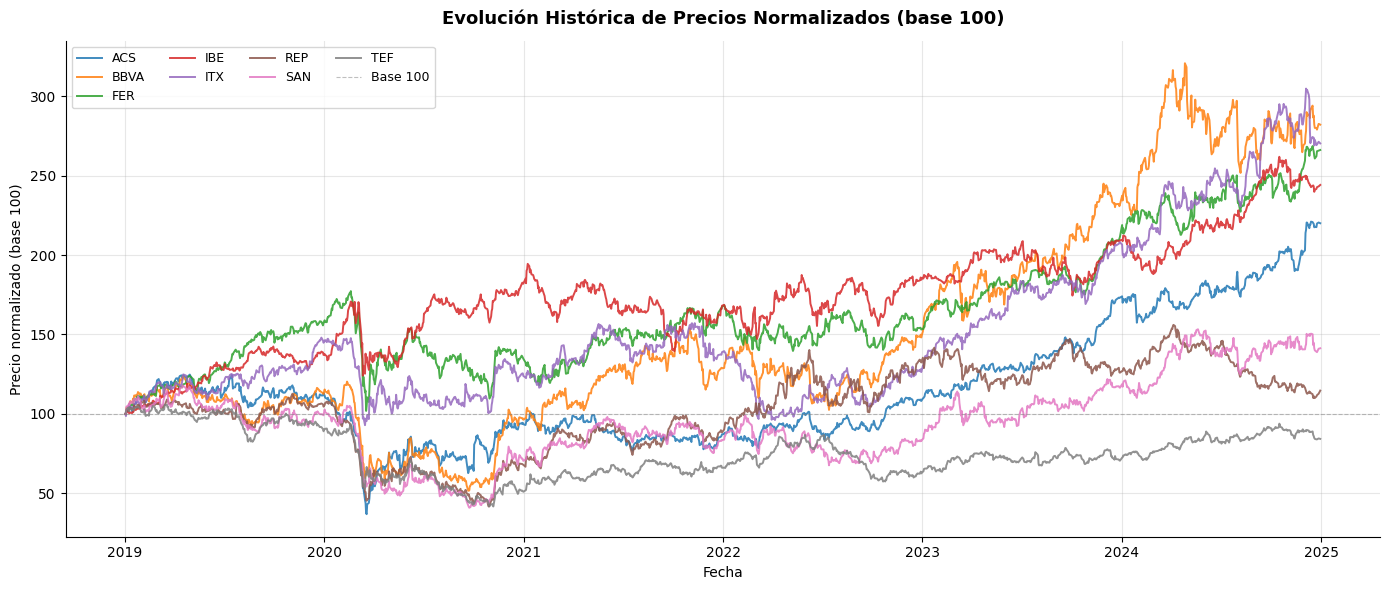

Gráfico guardado: evolucion_precios_normalizados.png


In [77]:
# Normalización de precios a base 100 en la primera fecha
# Permite comparar visualmente la evolución relativa de cada activo
prices_norm = prices_raw / prices_raw.iloc[0] * 100

fig, ax = plt.subplots(figsize=(14, 6))

for ticker in prices_norm.columns:
    ax.plot(prices_norm.index, prices_norm[ticker],
            label=ticker.replace('.MC', ''), linewidth=1.4, alpha=0.85)

ax.axhline(100, color='gray', linestyle='--', linewidth=0.8, alpha=0.5,
           label='Base 100')
ax.set_title('Evolución Histórica de Precios Normalizados (base 100)',
             fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Fecha')
ax.set_ylabel('Precio normalizado (base 100)')
ax.legend(ncol=4, fontsize=9, loc='upper left')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout()
plt.savefig('evolucion_precios_normalizados.png', dpi=150, bbox_inches='tight')
plt.show()
print('Gráfico guardado: evolucion_precios_normalizados.png')


## 7. Preprocesado de datos

El módulo de preprocesado aplica un pipeline de **5 pasos** sobre los precios brutos
para producir un dataset limpio y listo para el cálculo de rendimientos.

| Paso | Operación | Justificación |
|------|-----------|---------------|
| 1 | Eliminar activos con >20% de nulos | Activos con muchos huecos sesgan la matriz de covarianzas |
| 2 | Interpolación lineal (máx. 5 días) | Cubre festivos locales y suspensiones puntuales |
| 3 | Eliminar filas enteramente nulas | Festivos globales sin cotización en ningún activo |
| 4 | Eliminar duplicados en el índice | Evita errores en operaciones de ventana deslizante |
| 5 | Reindexar a días hábiles (lun–vie) | Garantiza continuidad temporal para el modelo de Markowitz |


In [78]:
# Ejecutar el pipeline de preprocesado
prices_clean = pipeline.preprocess(
    prices_raw,
    min_valid_ratio  = 0.80,   # eliminar activos con >20% de nulos
    max_consec_nulls = 5,      # interpolar hasta 5 días consecutivos
)

print(f'Shape bruto   : {prices_raw.shape}')
print(f'Shape limpio  : {prices_clean.shape}')
print(f'Nulos brutos  : {prices_raw.isna().sum().sum()}')
print(f'Nulos limpios : {prices_clean.isna().sum().sum()}')
print(f'Filas añadidas por reindexado: {len(prices_clean) - len(prices_raw)}')


19:30:14  [INFO]  Preprocesado — shape inicial: (1536, 8)
19:30:14  [INFO]  Paso 1 — Todos los activos superan el umbral de calidad.
19:30:14  [INFO]  Paso 2 — Interpolación: 0 nulos corregidos.
19:30:14  [INFO]  Paso 3 — Filas nulas eliminadas: 0.
19:30:14  [INFO]  Paso 5 — Reindexado: 28 filas añadidas.
19:30:14  [INFO]  Preprocesado completado — shape: (1564, 8) | nulos residuales: 64
19:30:14  [WARNING]  64 nulos residuales (huecos > 5 días). Revisar activos afectados.
19:30:14  [INFO]  Datos limpios guardados: prices_clean_2019-01-01_2024-12-31_1d.csv


Shape bruto   : (1536, 8)
Shape limpio  : (1564, 8)
Nulos brutos  : 0
Nulos limpios : 64
Filas añadidas por reindexado: 28


### Inspección del dataset preprocesado

Comparamos los precios brutos y limpios para verificar el resultado del preprocesado.

In [79]:
# Comparación antes/después del preprocesado
print('Nulos por activo — ANTES del preprocesado:')
null_before = prices_raw.isna().sum()
print(null_before[null_before > 0].to_string() if null_before.sum() > 0
      else '  Sin valores nulos en los datos descargados.')
print()
print('Nulos por activo — DESPUÉS del preprocesado:')
null_after = prices_clean.isna().sum()
print(null_after[null_after > 0].to_string() if null_after.sum() > 0
      else '  Sin valores nulos tras el preprocesado.')
print()
print('Primeras 5 filas de precios limpios:')
print(prices_clean.head())
print()
print('Últimas 5 filas de precios limpios:')
print(prices_clean.tail())


Nulos por activo — ANTES del preprocesado:
  Sin valores nulos en los datos descargados.

Nulos por activo — DESPUÉS del preprocesado:
ACS.MC     8
BBVA.MC    8
FER.MC     8
IBE.MC     8
ITX.MC     8
REP.MC     8
SAN.MC     8
TEF.MC     8

Primeras 5 filas de precios limpios:
            ACS.MC  BBVA.MC  FER.MC  IBE.MC  ITX.MC  REP.MC  SAN.MC  TEF.MC
Date                                                                       
2019-01-02 20.9031   3.1369 15.0195  5.1173 17.7379  8.9691  3.0204  4.3287
2019-01-03 20.9534   3.1453 15.0958  5.1261 17.4848  8.9817  3.0447  4.4006
2019-01-04 21.2678   3.2627 15.2781  5.1641 18.1016  9.1959  3.1586  4.4579
2019-01-07 21.3370   3.2513 15.3926  5.2036 18.2440  9.1203  3.1764  4.4982
2019-01-08 21.5571   3.2789 15.5411  5.1846 18.6394  9.1298  3.2026  4.4912

Últimas 5 filas de precios limpios:
            ACS.MC  BBVA.MC  FER.MC  IBE.MC  ITX.MC  REP.MC  SAN.MC  TEF.MC
Date                                                                       
20

### Visualización — Comparativa de precios brutos vs. limpios

Normalizamos ambas series a base 100 para visualizar el efecto del preprocesado
sobre la continuidad de las series temporales.

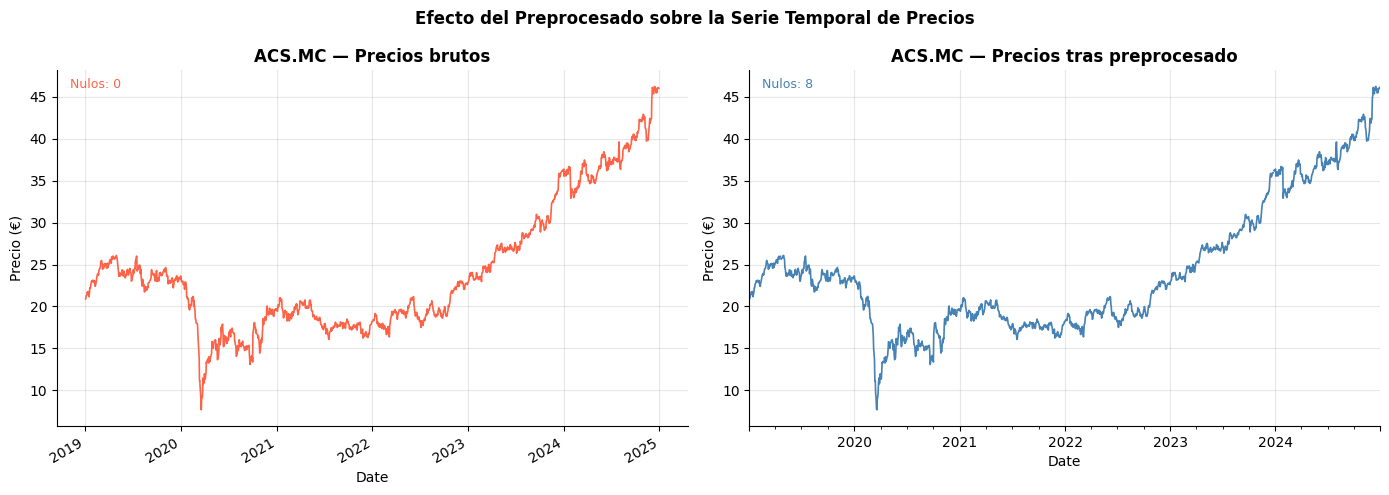

Gráfico guardado: comparativa_preprocesado.png


In [80]:
# Seleccionar un activo para comparar visualmente
activo_ref = prices_clean.columns[0]   # primer activo disponible

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel izquierdo: precios brutos
prices_raw[activo_ref].plot(ax=axes[0], color='tomato', linewidth=1.2)
axes[0].set_title(f'{activo_ref} — Precios brutos', fontweight='bold')
axes[0].set_ylabel('Precio (€)')
nulos = prices_raw[activo_ref].isna().sum()
axes[0].annotate(f'Nulos: {nulos}', xy=(0.02, 0.95),
                 xycoords='axes fraction', fontsize=9, color='tomato')

# Panel derecho: precios limpios
prices_clean[activo_ref].plot(ax=axes[1], color='steelblue', linewidth=1.2)
axes[1].set_title(f'{activo_ref} — Precios tras preprocesado', fontweight='bold')
axes[1].set_ylabel('Precio (€)')
nulos_clean = prices_clean[activo_ref].isna().sum()
axes[1].annotate(f'Nulos: {nulos_clean}', xy=(0.02, 0.95),
                 xycoords='axes fraction', fontsize=9, color='steelblue')

plt.suptitle('Efecto del Preprocesado sobre la Serie Temporal de Precios',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('comparativa_preprocesado.png', dpi=150, bbox_inches='tight')
plt.show()
print('Gráfico guardado: comparativa_preprocesado.png')


## 8. Cálculo de rendimientos logarítmicos diarios

Los rendimientos logarítmicos diarios se calculan como:

$$r_t = \ln\left(\frac{P_t}{P_{t-1}}\right)$$

donde $P_t$ es el precio de cierre ajustado en la fecha $t$.

**¿Por qué logarítmico y no aritmético?**
- **Aditividad temporal**: $\sum r_t = \ln(P_T/P_0)$, facilita la anualización.
- **Simetría**: subidas y bajadas del mismo porcentaje producen valores simétricos.
- **Estándar académico**: input habitual del modelo de Markowitz y la literatura de finanzas cuantitativas.

In [81]:
# Los rendimientos se calculan sobre los precios LIMPIOS (preprocesados)
# (no sobre los brutos) para evitar distorsiones por nulos y festivos
returns = pipeline.compute_returns(prices_clean)

print(f'Shape de rendimientos : {returns.shape}')
print(f'Media diaria (media)  : {returns.mean().mean():.6f}')
print(f'Std diaria (media)    : {returns.std().mean():.6f}')
print()
print('Primeras 5 filas de rendimientos:')
print(returns.head().round(6))


19:30:15  [INFO]  Calculando rendimientos logarítmicos...
19:30:15  [INFO]  Rendimientos: 1563 obs × 8 activos | media=0.000407 | std=0.018782
19:30:15  [INFO]  Rendimientos guardados: returns_2019-01-01_2024-12-31_1d.csv


Shape de rendimientos : (1563, 8)
Media diaria (media)  : 0.000407
Std diaria (media)    : 0.018782

Primeras 5 filas de rendimientos:
            ACS.MC  BBVA.MC  FER.MC  IBE.MC  ITX.MC  REP.MC  SAN.MC  TEF.MC
Date                                                                       
2019-01-03  0.0024   0.0027  0.0051  0.0017 -0.0144  0.0014  0.0080  0.0165
2019-01-04  0.0149   0.0366  0.0120  0.0074  0.0347  0.0236  0.0367  0.0129
2019-01-07  0.0032  -0.0035  0.0075  0.0076  0.0078 -0.0083  0.0056  0.0090
2019-01-08  0.0103   0.0084  0.0096 -0.0037  0.0214  0.0010  0.0082 -0.0016
2019-01-09  0.0087   0.0134  0.0044 -0.0109  0.0114  0.0140 -0.0043 -0.0206


### Visualización — Distribución de rendimientos diarios

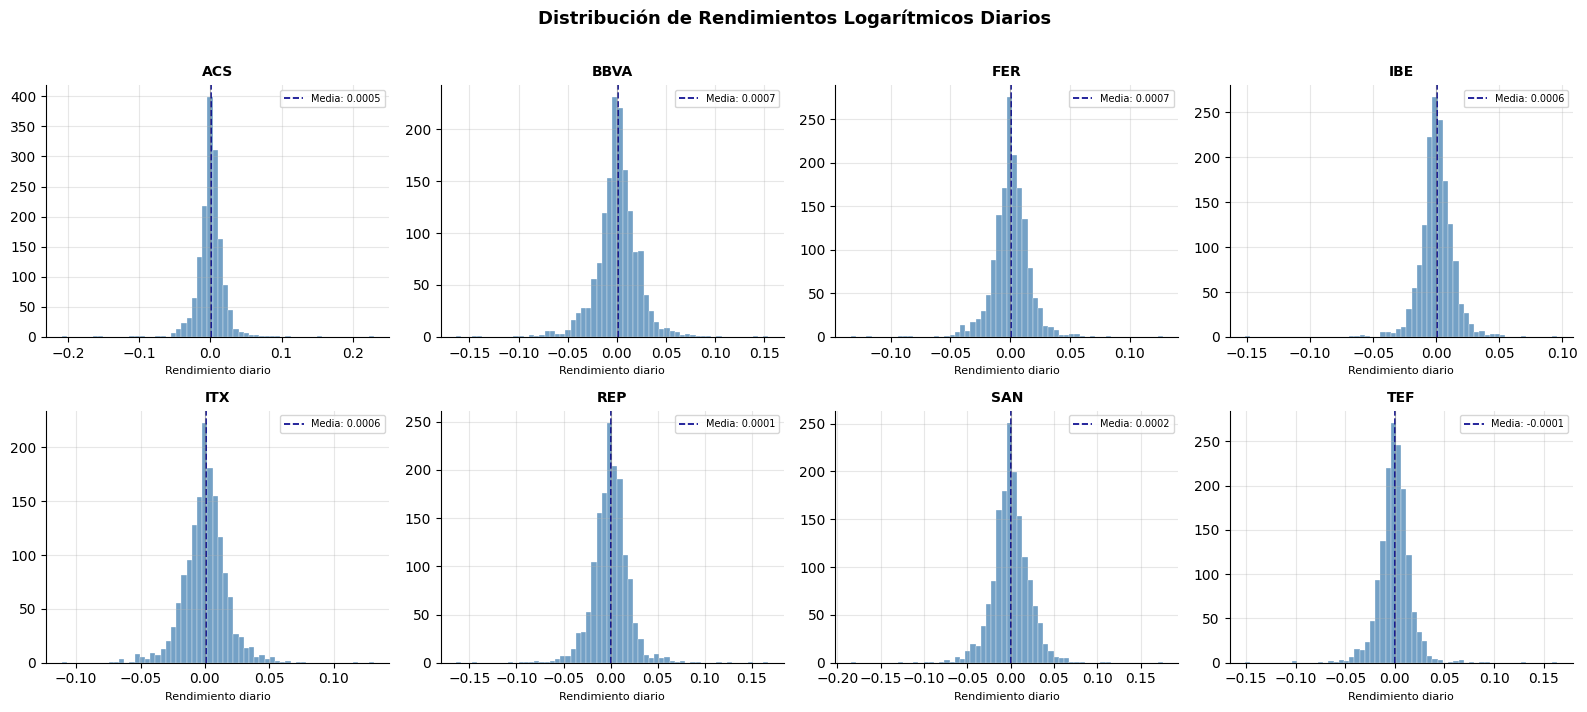

Gráfico guardado: distribucion_rendimientos.png


In [82]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

for i, ticker in enumerate(returns.columns):
    ax = axes[i]
    ret_serie = returns[ticker].dropna()

    # Histograma de rendimientos
    ax.hist(ret_serie, bins=60, color='steelblue', alpha=0.75,
            edgecolor='white', linewidth=0.3)

    # Línea de media
    ax.axvline(ret_serie.mean(), color='darkblue', linestyle='--',
               linewidth=1.2, label=f'Media: {ret_serie.mean():.4f}')

    # Línea de cero
    ax.axvline(0, color='gray', linestyle='-', linewidth=0.8, alpha=0.5)

    ax.set_title(ticker.replace('.MC', ''), fontsize=10, fontweight='bold')
    ax.set_xlabel('Rendimiento diario', fontsize=8)
    ax.legend(fontsize=7)

plt.suptitle('Distribución de Rendimientos Logarítmicos Diarios',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('distribucion_rendimientos.png', dpi=150, bbox_inches='tight')
plt.show()
print('Gráfico guardado: distribucion_rendimientos.png')


## 9. Estadísticas descriptivas anualizadas

Calculamos las métricas estadísticas clave que se mostrarán en el panel
EDA del dashboard del Proyecto Athena.

In [83]:
# Calcular estadísticas anualizadas
stats = pipeline.compute_annualized_stats(returns)

print('Estadísticas descriptivas anualizadas (252 días hábiles):')
print('=' * 75)
print(stats.to_string())


Estadísticas descriptivas anualizadas (252 días hábiles):
         Rendimiento anual (%)  Volatilidad anual (%)  Ratio de Sharpe  Asimetría  Curtosis  Máx. Drawdown (%)
ACS.MC                 12.8600                32.7500           0.3927    -0.1180   25.6100           -73.0900
BBVA.MC                17.3000                36.2700           0.4770    -0.3420    7.3706           -62.8100
FER.MC                 16.4500                25.2700           0.6510    -0.5718   10.2977           -45.0100
IBE.MC                 14.3300                21.3000           0.6728    -0.8150   14.4269           -30.9400
ITX.MC                 15.4200                27.5100           0.5605     0.2314    5.8846           -46.0600
REP.MC                  1.9000                33.0800           0.0574     0.1106   10.8942           -66.7300
SAN.MC                  6.1300                35.3200           0.1736    -0.2149    7.8547           -69.2700
TEF.MC                 -2.4400                27.0300 

### Visualización — Mapa de calor de correlaciones entre activos

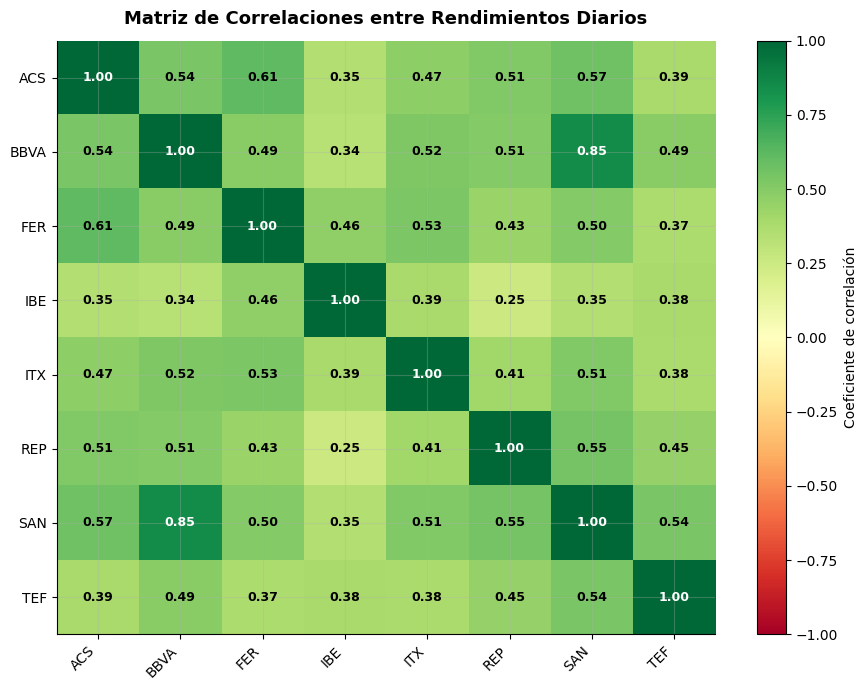

Gráfico guardado: matriz_correlaciones.png


In [84]:
# Matriz de correlaciones entre rendimientos diarios
corr_matrix = returns.corr()

# Renombrar columnas para el gráfico (sin sufijo .MC)
labels = [t.replace('.MC', '') for t in corr_matrix.columns]

fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(corr_matrix.values, cmap='RdYlGn', vmin=-1, vmax=1, aspect='auto')

# Anotaciones con los valores de correlación
for i in range(len(labels)):
    for j in range(len(labels)):
        val = corr_matrix.values[i, j]
        color = 'white' if abs(val) > 0.65 else 'black'
        ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                fontsize=9, color=color, fontweight='bold')

ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=10)
ax.set_yticklabels(labels, fontsize=10)
ax.set_title('Matriz de Correlaciones entre Rendimientos Diarios',
             fontsize=13, fontweight='bold', pad=12)

plt.colorbar(im, ax=ax, label='Coeficiente de correlación')
plt.tight_layout()
plt.savefig('matriz_correlaciones.png', dpi=150, bbox_inches='tight')
plt.show()
print('Gráfico guardado: matriz_correlaciones.png')


## 10. Resumen y outputs para el Hito 4

El pipeline del Hito 3 produce dos DataFrames que son el input directo
del **Módulo de Optimización de Markowitz (Hito 4)**:

| Output | Variable | Shape | Descripción |
|--------|----------|-------|-------------|
| Precios ajustados | `prices` | (N_días, N_activos) | Input para el preprocesado (Hito siguiente) |
| Rendimientos log. | `returns` | (N_días-1, N_activos) | Input directo para Markowitz (Hito 4) |

### Cómo usar estos outputs en el Hito 4

```python
# Hito 4 — Optimización de Markowitz
# Vector de rendimientos esperados (anualizado)
mu    = returns.mean() * 252

# Matriz de covarianzas (anualizada)
sigma = returns.cov() * 252

# -> Minimizar la varianza de la cartera sujeto a restricciones de pesos
# -> scipy.optimize.minimize(fun=portfolio_variance, constraints=...)
```

In [85]:
print('=' * 65)
print('  RESUMEN DEL HITO 3 — Adquisición y Preprocesado de Datos')
print('=' * 65)
print(f'  Activos en cartera    : {len(returns.columns)}')
print(f'  Período descargado    : {prices_raw.index.min().date()} -> {prices_raw.index.max().date()}')
print(f'  Días brutos           : {len(prices_raw)}')
print(f'  Días tras preprocesado: {len(prices_clean)}')
print(f'  Nulos en brutos       : {prices_raw.isna().sum().sum()}')
print(f'  Nulos tras preprocesado: {prices_clean.isna().sum().sum()}')
print(f'  Observaciones retorno : {len(returns)}')
print()
print('  Variables listas para Hito 4:')
print(f'    prices_raw.shape   = {prices_raw.shape}   (precios brutos)')
print(f'    prices_clean.shape = {prices_clean.shape}   (precios limpios)')
print(f'    returns.shape      = {returns.shape}   (rendimientos log)')
print()
print('  Archivos CSV generados en data/cache/:')
if Path(data).exists():
    for f in sorted(Path(data).iterdir()):
        size_kb = f.stat().st_size / 1024
        print(f'    {f.name:<55} ({size_kb:.1f} KB)')
print('=' * 65)


  RESUMEN DEL HITO 3 — Adquisición y Preprocesado de Datos
  Activos en cartera    : 8
  Período descargado    : 2019-01-02 -> 2024-12-30
  Días brutos           : 1536
  Días tras preprocesado: 1564
  Nulos en brutos       : 0
  Nulos tras preprocesado: 64
  Observaciones retorno : 1563

  Variables listas para Hito 4:
    prices_raw.shape   = (1536, 8)   (precios brutos)
    prices_clean.shape = (1564, 8)   (precios limpios)
    returns.shape      = (1563, 8)   (rendimientos log)

  Archivos CSV generados en data/cache/:
    prices_clean_2019-01-01_2024-12-31_1d.csv               (240.4 KB)
    prices_raw_2019-01-01_2024-12-31_1d.csv                 (238.7 KB)
    returns_2019-01-01_2024-12-31_1d.csv                    (272.8 KB)
